# Leonardo job-cost estimator

What is the wall-clock time the billed local-hours on our CINECA project for a specific WALRUS run? Let's find out!

`boost_usr_prod` has no `TRESBillingWeights`, so Slurm falls to `billing = cpu`. Every boost job reports `billing = 32 x nodes`, regardless of how many GPUs were asked for.

$$\text{billed local-hours} \;=\; 32 \times \text{nodes} \times \text{wall-hours}$$

`BatchedMultisetSampler.__len__` returns `max_samples` directly (`walrus/data/mixed_dset_sampler.py:212-220`, with `recycle=True`), so every rank draws `max_samples` micro-batches per epoch regardless of world size. Adding nodes does not make an epoch finish sooner.

So for instance, the stats below are from three actual runs:

| nodes | train / epoch | one-step val | rollout val | billed for 100 epochs |
|---|---|---|---|---|
| 1 | 6892 s | 149 s | 1800 s | ~6,500 h |
| 4 | 7382 s | 148 s | 826 s | ~27,000 h |
| 8 | 7947 s | 137 s | 488 s | ~58,000 h |

## 0. Setup

In [1]:
import glob, json, os, re, shlex, subprocess, math, warnings
from datetime import datetime

warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)

REPO         = "/leonardo/home/userexternal/sshamsi0/MHPC_Thesis"
SCRATCH_LOGS = "/leonardo_scratch/fast/ICT26_MHPC/sshamsi/logs"
WANDB_DIR    = f"{SCRATCH_LOGS}/wandb"
SLURM_DIR    = f"{SCRATCH_LOGS}/slurm"
HYDRA_DIR    = f"{REPO}/walrus/outputs"
SCRIPT_DIR   = f"{REPO}/LeonardoRunScripts"
CACHE_DIR    = f"{REPO}/demo_notebooks/.cost_cache"

# boost_usr_prod: billing == cpu == 32 per node (verified against saldo to 0.02%).
BILLING_PER_NODE = 32
GPUS_PER_NODE    = 4
QOS_WALLTIME_S   = {"normal": 24 * 3600, "boost_qos_dbg": 30 * 60}

os.makedirs(CACHE_DIR, exist_ok=True)
print("cache:", CACHE_DIR)

cache: /leonardo/home/userexternal/sshamsi0/MHPC_Thesis/demo_notebooks/.cost_cache


## 1. Harvest past runs

We read data from 4 places total and write everything to `.cost_cache/`.

| Source | Count | Gives |
|---|---|---|
| `LeonardoRunScripts/**/*.sh` | ~36 | SBATCH headers + Hydra overrides — the feature vector for *proposed* runs |
| `logs/wandb/offline-run-*/files/` | 41 | `wandb-metadata.json` (`args`, `slurm.job_num_nodes`), `wandb-summary.json` (`avg_time_per_step`), `output.log` |
| `walrus/outputs/<date>/<time>/` | 87 | `.hydra/overrides.yaml` + `train.log` — covers the July runs W&B misses |
| `logs/slurm/<job>/<id>.out` | 42 | job-id ↔ job-name link for the sacct join |

`wandb-metadata.json`'s `args` field is literally just the Hydra CLI override list. Thus, `parse_overrides()` serves both past runs and proposed runs, and they live in the same feature space.

In [2]:
# Hydra override key -> short feature name.
FEATURES = {
    "name": "name", "distribution": "distribution", "data": "data_cfg",
    "model.hidden_dim": "hidden_dim", "model.processor_blocks": "blocks",
    "model.processor.space_mixing.mlp_dim": "mlp_dim",
    "model.processor.space_mixing.num_heads": "heads",
    "model.gradient_checkpointing_freq": "gc_freq",
    "model.projection_dim": "projection_dim",
    "model.intermediate_dim": "intermediate_dim",
    "model.groups": "groups", "model.override_dimensionality": "override_d",
    "model/processor/space_mixing": "space_mixing",
    "data.module_parameters.batch_size": "batch_size",
    "data.module_parameters.max_samples": "max_samples",
    "data.module_parameters.n_steps_input": "n_steps_input",
    "data.module_parameters.n_steps_output": "n_steps_output",
    "trainer.max_epoch": "max_epoch", "trainer.grad_acc_steps": "grad_acc_steps",
    "trainer.val_frequency": "val_frequency",
    "trainer.rollout_val_frequency": "rollout_val_frequency",
    "trainer.short_validation_length": "short_validation_length",
    "trainer.max_rollout_steps": "max_rollout_steps",
    "trainer.log_interval": "log_interval", "trainer.enable_amp": "enable_amp",
    "trainer.video_validation": "video_validation",
    "trainer.prediction_type": "prediction_type",
    "validation_mode": "validation_mode", "finetuning_mods": "finetuning_mods",
    "checkpoint": "checkpoint", "experiment": "experiment",
    "data_workers": "data_workers", "logger.wandb_project_name": "wandb_project",
}

INT_COLS = ["hidden_dim", "blocks", "mlp_dim", "heads", "gc_freq", "projection_dim",
            "intermediate_dim", "groups", "batch_size", "max_samples",
            "n_steps_input", "n_steps_output", "max_epoch", "grad_acc_steps",
            "val_frequency", "rollout_val_frequency", "short_validation_length",
            "max_rollout_steps", "log_interval", "data_workers", "nodes",
            "gpus_per_node", "override_d"]
BOOL_COLS = ["enable_amp", "video_validation", "validation_mode"]


def _coerce(d):
    out = dict(d)
    for k in INT_COLS:
        if isinstance(out.get(k), str):
            try:
                out[k] = int(float(out[k]))
            except ValueError:
                pass
    for k in BOOL_COLS:
        if isinstance(out.get(k), str):
            out[k] = out[k].strip().lower() in ("true", "1", "yes")
    return out


def parse_overrides(args):
    """Hydra CLI override list -> feature dict."""
    raw = {}
    for tok in args:
        tok = tok.strip()
        if "=" not in tok:
            continue
        k, v = tok.split("=", 1)
        raw[k.lstrip("+")] = v.strip().strip('"').strip("'")   # ++x / +x forms
    feats = {short: raw.get(long) for long, short in FEATURES.items()}
    feats["_overrides"] = raw
    return _coerce(feats)


def _hms(s):
    """SLURM time string -> seconds. Handles D-HH:MM:SS and HH:MM:SS."""
    if not s:
        return None
    days = 0
    if "-" in s:
        d, s = s.split("-", 1)
        days = int(d)
    p = [int(x) for x in s.split(":")]
    while len(p) < 3:
        p.insert(0, 0)
    return days * 86400 + p[-3] * 3600 + p[-2] * 60 + p[-1]


def parse_run_script(path):
    """Parse a LeonardoRunScripts .sh into the same feature dict shape."""
    if not os.path.isabs(path):
        path = os.path.join(REPO, path)
    text = open(path, errors="ignore").read()
    sb = dict(re.findall(r"^#SBATCH\s+--([\w-]+)=(\S+)", text, re.M))
    # Strip comments so commented-out overrides are not picked up.
    body = "\n".join(l for l in text.splitlines() if not l.lstrip().startswith("#"))
    m = re.search(r"train\.py\s*\\?\s*\n(.*?)(?:\n\s*\n|\Z)", body, re.S)
    args = []
    if m:
        chunk = m.group(1).replace("\\\n", " ").replace("\\", " ")
        try:
            args = shlex.split(chunk)
        except ValueError:
            args = chunk.split()
    f = parse_overrides(args)
    f["source"] = "script"
    f["script"] = os.path.relpath(path, REPO)
    f["job_name"] = sb.get("job-name")
    f["nodes"] = int(sb.get("nodes", 1))
    f["gpus_per_node"] = int(sb.get("gpus-per-node", GPUS_PER_NODE))
    f["qos"] = sb.get("qos")
    f["walltime_s"] = _hms(sb.get("time"))
    f.setdefault("name", f["job_name"])
    if f.get("name") is None:
        f["name"] = f["job_name"]
    return _coerce(f)


scripts = pd.DataFrame([
    parse_run_script(p)
    for p in sorted(glob.glob(f"{SCRIPT_DIR}/**/*.sh", recursive=True))
    if parse_run_script(p).get("_overrides")
])
print(f"{len(scripts)} run scripts parsed")
scripts[["script", "nodes", "hidden_dim", "blocks", "gc_freq", "data_cfg",
         "max_samples", "max_epoch", "validation_mode"]].head(12)

36 run scripts parsed


,script,nodes,hidden_dim,blocks,gc_freq,data_cfg,max_samples,max_epoch,validation_mode
0,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_MHD_64,NaN,NaN,None
1,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_acoustic_scattering_discontinuous,NaN,NaN,None
2,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_active_matter,NaN,NaN,None
3,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_gray_scott_reaction_diffusion,NaN,NaN,None
4,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_helmholtz_staircase,NaN,NaN,None
5,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_planetswe,NaN,NaN,None
6,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_turbulent_radiative_layer_2D,NaN,NaN,None
7,LeonardoRunScripts/InitialValidatePretrained/v...,1,1408,40,2,Leonardo_viscoelastic_instability,NaN,NaN,None
8,LeonardoRunScripts/fullDims_6DS.sh,1,1408,40,2,Leonardo_smallest8_2_3d,2000.0,71.0,None
9,LeonardoRunScripts/fullDims_6DS_N4.sh,4,1408,40,2,Leonardo_smallest8_2_3d,2000.0,71.0,None


### 1.1 Log parsing

The trainer outputs some time logs every `log_interval` steps (`walrus/trainer/training.py:1137-1141`) plus phase-boundary log lines.

- `total_time` on the training line is the interval mean `(now - interval_start) / log_interval` (mean seconds-per-micro-batch). The `data`/`fwd`/`bw`/`opt` values printed beside it are instantaneous values from one step, so we use `total_time` and ignore the rest for cost purposes.
- The first logged interval of each epoch is discarded as it absorbs dataloader warm-up and checkpoint load.
- In the case of multiple ranks, all ranks write into one file and interleave out of order, so phase boundaries take the earliest timestamp seen per `(epoch, marker)`.

In [3]:
TS      = re.compile(r"^\[(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d),(\d+)\]")
PHASE   = re.compile(r"Epoch (\d+)/(\d+): (starting training|training loss|"
                     r"starting valid validation|valid loss|"
                     r"starting rollout valid validation|rollout valid loss)")
STEP    = re.compile(
    r"Epoch\s+(\d+), Batch (\d+)/(\d+), Rank\s+(\d+), SyncStep: (True|False):\s*"
    r"\n?\s*Data: (\S+)\s*, loss\s+([\d.naif]+), mem\s+([\d.]+) GB, "
    r"total_time\s+([\d.]+)s, data\s+([\d.]+)s, fwd\s+([\d.]+)s, "
    r"bw\s+([\d.]+)s, opt\s+([\d.]+)s")
VALSTEP = re.compile(
    r"(valid|test): (\S+), Batch (\d+)/(\d+), Rank\s+(\d+): "
    r"Field-time-averaged VRMSE\s+([\d.naif]+), mem\s+([\d.]+) GB, "
    r"total_time\s+([\d.]+)s, model\s+([\d.]+)s")
RUN_EXP = re.compile(r"Run experiment (\S+)")

PHASE_PAIRS = {"train":   ("starting training", "training loss"),
               "val":     ("starting valid validation", "valid loss"),
               "rollout": ("starting rollout valid validation", "rollout valid loss")}


def parse_log(path):
    """-> (per-step DataFrame, per-phase DataFrame)."""
    try:
        text = open(path, errors="ignore").read()
    except OSError:
        return pd.DataFrame(), pd.DataFrame()

    steps = [{
        "epoch": int(g[0]), "batch": int(g[1]), "n_batch": int(g[2]),
        "rank": int(g[3]), "sync": g[4] == "True", "dataset": g[5],
        "mem_gb": float(g[7]), "t_step": float(g[8]), "t_data": float(g[9]),
        "t_fwd": float(g[10]), "t_bw": float(g[11]), "t_opt": float(g[12]),
    } for g in (m.groups() for m in STEP.finditer(text))]

    marks = {}
    for line in text.splitlines():
        t, p = TS.match(line), PHASE.search(line)
        if not (t and p):
            continue
        ts = datetime.strptime(t.group(1), "%Y-%m-%d %H:%M:%S")
        key = (int(p.group(1)), p.group(3))
        if key not in marks or ts < marks[key]:
            marks[key] = ts

    phases = []
    for e in sorted({e for e, _ in marks}):
        for phase, (a_k, b_k) in PHASE_PAIRS.items():
            a, b = marks.get((e, a_k)), marks.get((e, b_k))
            if a and b and b >= a:
                phases.append({"epoch": e, "phase": phase,
                               "seconds": (b - a).total_seconds()})
    return pd.DataFrame(steps), pd.DataFrame(phases)


def parse_val_steps(path):
    try:
        text = open(path, errors="ignore").read()
    except OSError:
        return pd.DataFrame()
    return pd.DataFrame([{
        "kind": g[0], "dataset": g[1], "batch": int(g[2]), "denom": int(g[3]),
        "rank": int(g[4]), "mem_gb": float(g[6]), "t_total": float(g[7]),
        "t_model": float(g[8]),
    } for g in (m.groups() for m in VALSTEP.finditer(text))])

### 1.2 The Hydra-directory collision problem

Hydra names its output dir `outputs/<date>/<HH-MM-SS>/` — resolved only to the **second**.
Jobs launched in the same second therefore *share a directory and interleave their logs*.
**24 of 87 dirs are affected**, one of them holding 14 different runs across 6 different
`hidden_dim` values.

Left unhandled this silently corrupts the calibration: a run labelled
`halfDims_FT_ActiveMatter_N8` (`data=activematter_leonardo`, one dataset, `hidden_dim=1088`)
had `MHD_64` and `gray_scott` batches in its log and a step time matching the 1408-wide model.

A log is usable only if every architecture- and runtime-relevant setting it dumps has a
**single** value. If several runs shared a dir but agreed on all of those, the timing is
still attributable to that config — only the *name* is ambiguous, so we keep it and flag it.

In [4]:
CONTAMINATION_KEYS = {
    "hidden_dim": r"hidden_dim: (\d+)",
    "processor_blocks": r"processor_blocks: (\d+)",
    "gradient_checkpointing_freq": r"gradient_checkpointing_freq: (\d+)",
    "enable_amp": r"enable_amp: (\w+)",
    "batch_size": r"\n  batch_size: (\d+)",
    "grad_acc_steps": r"grad_acc_steps: (\d+)",
    "distribution_type": r"distribution_type: (\w+)",
}


def contamination(path):
    try:
        text = open(path, errors="ignore").read()
    except OSError:
        return 0, {}
    return (len(set(RUN_EXP.findall(text))),
            {k: len(set(re.findall(p, text))) for k, p in CONTAMINATION_KEYS.items()})


def infer_world_size(path):
    """Hydra logs record no node count; every rank writes to the same file, so
    the highest rank id seen + 1 is the world size."""
    try:
        text = open(path, errors="ignore").read()
    except OSError:
        return None
    m = re.search(r"world_size[\"']?\s*[:=]\s*(\d+)", text)
    if m:
        return int(m.group(1))
    ranks = {int(r) for r in re.findall(r"Rank\s+(\d+)", text)}
    return max(ranks) + 1 if ranks else None

### 1.3 Build the cache

In [5]:
def harvest_wandb():
    rows = []
    for d in sorted(glob.glob(f"{WANDB_DIR}/offline-run-*")):
        fdir = os.path.join(d, "files")
        mp = os.path.join(fdir, "wandb-metadata.json")
        if not os.path.exists(mp):
            continue
        meta = json.load(open(mp))
        r = parse_overrides(meta.get("args", []))
        r.update(source="wandb", run_dir=d, wandb_id=d.rsplit("-", 1)[-1],
                 log_path=os.path.join(fdir, "output.log"),
                 nodes=int(meta.get("slurm", {}).get("job_num_nodes", 1)),
                 gpus_per_node=meta.get("gpu_count"), host=meta.get("host"),
                 started_at=meta.get("started_at"))
        sp = os.path.join(fdir, "wandb-summary.json")
        if os.path.exists(sp):
            try:
                s = json.load(open(sp))
                for k in ("avg_time_per_step", "avg_forward_time",
                          "avg_backward_time", "peak_memory", "_runtime", "epoch"):
                    r[f"wb_{k.lstrip('_')}"] = s.get(k)
            except json.JSONDecodeError:
                pass
        rows.append(_coerce(r))
    return rows


def harvest_hydra():
    import yaml
    rows = []
    for log in sorted(glob.glob(f"{HYDRA_DIR}/*/*/train.log")):
        rd = os.path.dirname(log)
        ovp = os.path.join(rd, ".hydra", "overrides.yaml")
        if not os.path.exists(ovp):
            continue
        try:
            ov = yaml.safe_load(open(ovp))
        except yaml.YAMLError:
            continue
        if not isinstance(ov, list):
            continue
        r = parse_overrides(ov)
        r.update(source="hydra", run_dir=rd, log_path=log)
        rows.append(_coerce(r))
    return rows


def summarise_run(row):
    out = dict(row)
    path = out.get("log_path")
    if not path or not os.path.exists(path):
        return out

    n_runs, spread = contamination(path)
    out["log_n_runs"] = n_runs
    out["log_config_spread"] = max(spread.values()) if spread else 0
    out["contaminated"] = out["log_config_spread"] > 1
    out["ambiguous_name"] = n_runs > 1 and not out["contaminated"]
    if out["contaminated"]:
        return out

    sdf, pdf = parse_log(path)

    if out.get("source") == "hydra":
        ws = infer_world_size(path)
        if ws:
            out["world_size"] = ws
            out["nodes"] = max(1, ws // GPUS_PER_NODE)

    if len(sdf):
        first = sdf.groupby(["rank", "epoch"])["batch"].transform("min")
        steady = sdf[(sdf["batch"] > first) & (sdf["t_step"] > 0.01)]
        if len(steady):
            out["t_step_median"] = float(steady["t_step"].median())
            out["t_step_n"] = int(len(steady))
            out["peak_mem_gb"] = float(sdf["mem_gb"].max())
            out["t_step_by_dset"] = {k: round(float(v), 4) for k, v in
                                     steady.groupby("dataset")["t_step"].median().items()}
    if len(pdf):
        for ph in ("train", "val", "rollout"):
            sub = pdf[pdf["phase"] == ph]
            if len(sub):
                out[f"t_{ph}_epoch_median"] = float(sub["seconds"].median())
                out[f"t_{ph}_epoch_n"] = int(len(sub))
        out["epochs_observed"] = int(pdf["epoch"].nunique())

    vs = parse_val_steps(path)
    if len(vs):
        one = vs[vs["denom"] < 100]
        if len(one):
            out["t_val_batch_median"] = float(one["t_total"].median())
            out["val_datasets"] = int(one["dataset"].nunique())
            out["short_val_denom"] = int(one["denom"].median())
            out["t_val_by_dset"] = {k: round(float(v), 4) for k, v in
                                    one.groupby("dataset")["t_total"].median().items()}
    return out


RUNS_CACHE = f"{CACHE_DIR}/runs.pkl"
REBUILD = not os.path.exists(RUNS_CACHE)   # set True to force a re-scan

if REBUILD:
    raw = harvest_wandb() + harvest_hydra()
    runs = pd.DataFrame([summarise_run(r) for r in raw])
    runs.to_pickle(RUNS_CACHE)
    print(f"parsed {len(runs)} runs -> {RUNS_CACHE}")
else:
    runs = pd.read_pickle(RUNS_CACHE)
    print(f"loaded {len(runs)} runs from cache")

print(f"  contaminated (dropped):   {int(runs.contaminated.fillna(False).sum())}")
print(f"  ambiguous name (kept):    {int(runs.ambiguous_name.fillna(False).sum())}")
print(f"  with steady-state timing: {int(runs.t_step_median.notna().sum())}")

loaded 127 runs from cache
  contaminated (dropped):   5
  ambiguous name (kept):    18
  with steady-state timing: 91


## 2. Where the hours went

`sacct` is the billing ground truth. We read `billing=` out of `AllocTRES` rather than
assuming 32, so the arithmetic stays honest if a job ever had a different shape.

In [6]:
SACCT_CACHE = f"{CACHE_DIR}/sacct.csv"

if not os.path.exists(SACCT_CACHE):
    cmd = ["sacct", "-u", os.environ.get("USER", ""), "-S", "2026-02-01", "-X",
           "--format=JobID,JobName%50,ElapsedRaw,NNodes,State%20,AllocTRES%90,"
           "Start,End,Partition,Account", "-P"]
    open(SACCT_CACHE, "w").write(subprocess.run(cmd, capture_output=True, text=True).stdout)

acct = pd.read_csv(SACCT_CACHE, sep="|")
acct = acct[acct.Account.str.lower() == "ict26_mhpc_0"].copy()
acct["billing"] = acct.AllocTRES.fillna("").str.extract(r"billing=(\d+)").astype(float)
acct["billed_h"] = acct.ElapsedRaw / 3600 * acct.billing
acct["state0"] = acct.State.str.split().str[0]
acct["family"] = acct.JobName.str.replace(r"_\d+$", "", regex=True)

total = acct.billed_h.sum()
print(f"{len(acct)} jobs, {total:,.0f} billed local-hours")
print("(saldo -r reports 60,821 h for this user - agreement confirms the 32 x nodes formula)\n")

by_state = acct.groupby("state0").billed_h.agg(["size", "sum"]).sort_values("sum", ascending=False)
by_state["pct"] = by_state["sum"] / total * 100
print(by_state.round(1).to_string())

438 jobs, 60,811 billed local-hours
(saldo -r reports 60,821 h for this user - agreement confirms the 32 x nodes formula)



           size      sum   pct
state0                        
TIMEOUT      94  56283.1  92.6
FAILED      107   1790.1   2.9
NODE_FAIL     1   1237.6   2.0
COMPLETED    82   1067.1   1.8
CANCELLED   154    433.0   0.7


**93% of every hour spent went to a job that hit the wall limit and died.** Only 1.8%
of hours belong to jobs that reached `COMPLETED`.

That reframes the estimator's job: the useful question is not "how long will this take"
but "how many 24 h jobs will it take, and what is the total bill" — which is what §4 reports.

,jobs,billed_h,nodes,pct,cum_pct
family,,,,,
smallest7_2d_PT_BS2000_E100_N8,5,18476.4,8,30.4,30.4
fullDims_FT_ActiveMatter_N8,3,9257.4,8,15.2,45.6
smallest7_2d_PT_BS2000_E100_N4,5,9238.2,4,15.2,60.8
fullDims_6DS_N8,3,4694.3,8,7.7,68.5
fullDims_6DS_N4,3,4628.3,4,7.6,76.1
fullDims_FT_ActiveMatter_N4,3,4323.6,4,7.1,83.2
smallest7_2d_PT_BS2000_E100_N1,6,2310.1,1,3.8,87.0
fullDims_FT_ActiveMatter,11,1365.9,1,2.2,89.3
fullDims_6DS,3,1157.2,1,1.9,91.2


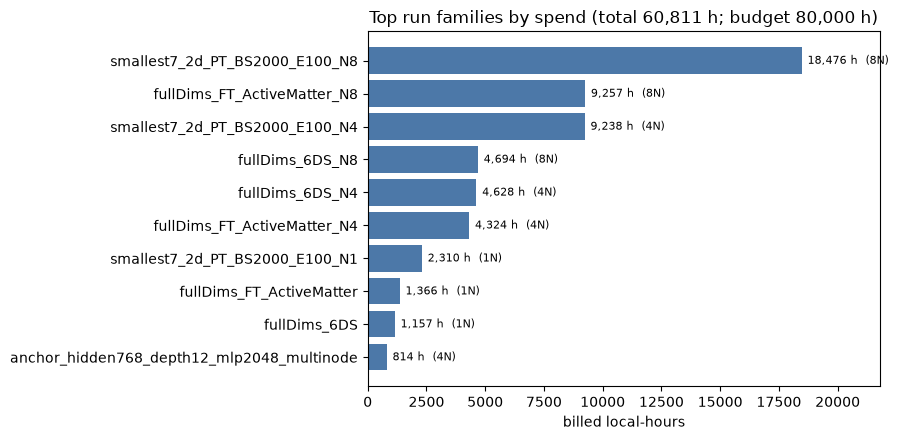

In [7]:
fam = acct.groupby("family").agg(jobs=("billed_h", "size"), billed_h=("billed_h", "sum"),
                                 nodes=("NNodes", "max")).sort_values("billed_h", ascending=False)
fam["pct"] = fam.billed_h / total * 100
fam["cum_pct"] = fam.pct.cumsum()
display(fam.head(15).round(1))

top = fam.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top.billed_h, color="#4C78A8")
ax.set_xlabel("billed local-hours")
ax.set_title(f"Top run families by spend (total {total:,.0f} h; budget 80,000 h)")
for y, (v, n) in enumerate(zip(top.billed_h, top.nodes)):
    ax.text(v + total * 0.004, y, f"{v:,.0f} h  ({n}N)", va="center", fontsize=8)
ax.margins(x=0.18)
plt.tight_layout(); plt.show()

### 2.1 The node-scaling penalty, measured

In [8]:
# The three smallest7_2d_PT runs are identical apart from node count -- a clean
# natural experiment in what multi-node actually bought.
sc = runs[runs.name.astype(str).str.startswith("smallest7_2d_PT_BS2000_E100_N")
          & (runs.source == "wandb")]
scal = sc.groupby("nodes").agg(
    train_epoch_s=("t_train_epoch_median", "median"),
    val_epoch_s=("t_val_epoch_median", "median"),
    rollout_epoch_s=("t_rollout_epoch_median", "median"),
    t_step_s=("t_step_median", "median")).round(1)

# Amortise validation over its frequency (val every 2 epochs, rollout every 5).
scal["epoch_s"] = (scal.train_epoch_s + scal.val_epoch_s / 2 + scal.rollout_epoch_s / 5)
scal["wall_h_100ep"] = scal.epoch_s * 100 / 3600
scal["billed_h_100ep"] = scal.wall_h_100ep * scal.index * BILLING_PER_NODE
scal["cost_vs_N1"] = (scal.billed_h_100ep / scal.billed_h_100ep.iloc[0]).round(2)
scal["wall_vs_N1"] = (scal.wall_h_100ep / scal.wall_h_100ep.iloc[0]).round(2)
display(scal.round(1))

print("Same wall-clock, N times the cost. Actual spend on this one experiment:")
print(fam.loc[fam.index.str.startswith("smallest7_2d_PT_BS2000_E100_N"),
              ["jobs", "billed_h", "pct"]].round(1).to_string())

,train_epoch_s,val_epoch_s,rollout_epoch_s,t_step_s,epoch_s,wall_h_100ep,billed_h_100ep,cost_vs_N1,wall_vs_N1
nodes,,,,,,,,,
1.0,6867.0,147.0,1799.5,3.4,7300.4,202.8,6489.2,1.0,1.0
4.0,7369.0,147.0,826.0,3.7,7607.7,211.3,27049.6,4.2,1.0
8.0,7944.5,137.0,488.5,4.0,8110.7,225.3,57676.1,8.9,1.1


Same wall-clock, N times the cost. Actual spend on this one experiment:
                                jobs  billed_h   pct
family                                              
smallest7_2d_PT_BS2000_E100_N8     5   18476.4  30.4
smallest7_2d_PT_BS2000_E100_N4     5    9238.2  15.2
smallest7_2d_PT_BS2000_E100_N1     6    2310.1   3.8


## 3. Calibrate the cost model

### Structure

```
steps_per_epoch  = max_samples                       # micro-batches PER RANK
t_train_epoch    = max_samples x t_step(cfg)
t_val_epoch      = n_datasets x short_validation_length x t_val_batch(cfg)   # ~flat in nodes
t_rollout_epoch  = rollout_cost(cfg, nodes)                                  # falls with nodes
wall  = max_epoch x (t_train_epoch + t_val_epoch/val_frequency
                     + t_rollout_epoch/rollout_val_frequency) + startup
billed_local_h = 32 x nodes x wall / 3600
```

### `t_step` — a FLOP proxy, not one-hot dummies

Fitting dummies per architecture cannot extrapolate to a shape never run (such as the
200M `hidden_dim=768, blocks=12` config, which has no completed job). So we regress on an
analytic forward-cost proxy built the same way as the parameter count in
`walrus_example_2_ArchitectureAndDimensions.ipynb` / `walrus_architecture_notes.md` §7, §11.

The vstride encoder adjusts strides per input so the token grid stays ~constant across
datasets of different native resolution, so token count is a constant rather than a
function of input resolution. The data bears this out: per-step time spans only **1.13×**
across the eight Well datasets (`active_matter` 3.23 s → `MHD_64` 3.66 s at 1408/40),
because `MHD_64` also carries `batch_downsample_factor: 0.5` in the mixture config.

In [9]:
N_TOKENS = 64   # Gh x Gw x Gd out of the vstride encoder for 2D data (notes §7)


def flop_proxy(hidden_dim, blocks, mlp_dim=None, n_steps_input=6,
               intermediate_dim=352, n_tokens=N_TOKENS):
    """Relative forward-pass cost (arbitrary units; scale absorbed by the intercept)."""
    H, T, N = float(hidden_dim), float(n_steps_input or 6), float(n_tokens)
    mlp = float(mlp_dim) if mlp_dim and not pd.isna(mlp_dim) else 4.0 * H
    space = 4.0 * N * T * H**2 + 2.0 * N**2 * T * H      # qkv/proj + attention
    time_ = 4.0 * N * T * H**2 + 2.0 * T**2 * N * H
    mlp_f = 2.0 * N * T * H * mlp
    I = float(intermediate_dim or 352)
    encdec = 2.0 * (2.0 * N * T * (I * H + I * 64.0))
    return float(blocks) * (space + time_ + mlp_f) + encdec


def gc_recompute_fraction(gc_freq, blocks):
    """Block i is checkpointed when i % gc_freq == 0 (isotropic_model.py:131-135),
    so the recomputed fraction of the processor is ceil(blocks/gc_freq)/blocks."""
    if not gc_freq or pd.isna(gc_freq) or gc_freq <= 0:
        return 0.0
    return math.ceil(float(blocks) / float(gc_freq)) / float(blocks)

#### One confound worth calling out

Before controlling for **`trainer.enable_amp`**, `gc_freq` looked *non-monotonic* —
`gc=1` appeared faster than `gc=2`, which is physically backwards. The July runs used AMP;
the August production runs set `enable_amp=False`. Controlling for it restores the expected
ordering and makes gradient checkpointing cleanly identifiable:

| config | gc_freq | s/step |
|---|---|---|
| 768/12/2048, AMP, ddp | 0 | 0.874 |
| 768/12/2048, AMP, ddp | 1 (every block) | 1.093 |

i.e. full checkpointing costs **+25%** in time. `REF_DATASET` is the baseline absorbed into
the intercept.

#### Why `distribution` and `grad_acc_steps` were dropped, and ridge is now cross-validated

An earlier version of this model included `distribution` (`fsdp`/`ddp`) and `grad_acc_steps`
as predictors, fit with a fixed `ridge=1e-3`. Checking that fit's condition number
(**~4100** — textbook "severe" starts at 100) and per-predictor VIFs turned up a real
problem: `log_proxy`, the architecture-scaling term this whole model exists to estimate,
had **VIF 18.1**; `log_bs` **16.6**; `fsdp` **10.7** (VIF > 10 means over 90% of a
predictor's variation is linearly explained by the *other* predictors). Architecture size,
batch size, AMP and distribution are almost one axis in this data, not four independent
ones: every `ddp` row is the 768/12 architecture, and every `grad_acc_steps=1` row is the
fine-tuning family (which also differs in `drop_path`, `checkpoint`, the LR schedule, ...).

The fixed `ridge=1e-3` turned out too weak to matter — its coefficients were identical to
plain OLS to 4 decimal places — yet dropping the penalty entirely exposed what that
barely-there difference was containing: `walrus_full_dimension`, the sole `ddp`+AMP+1408/40
family, hit **14,346% error** under plain OLS when left out of a leave-one-family-out
check (vs. 54% with `ridge=1e-3` — near a collinear design matrix, coefficient shifts too
small to show up at 4 decimals get hugely amplified on a held-out prediction that falls
outside the training pattern).

Two changes follow: **(1)** drop `distribution` and `grad_acc_steps` — neither is
identified independently of everything else already in the model, and removing them caps
the worst-case leave-one-family-out error at ~12.5% even with **zero** regularisation;
**(2)** select the ridge strength by grid-searching leave-one-family-out error instead of
guessing a fixed value.

In [10]:
REF_DATASET = "active_matter"


def dataset_levels(df):
    return sorted(d for d in df["dataset"].dropna().unique() if d != REF_DATASET)


def design_matrix(df, dsets=None):
    """log t_step = b0 + b1 log(proxy) + b2 log(bs) + b_fp32
                    + b_gc*recompute + b_node log2(nodes) + per-dataset effects

    `distribution` and `grad_acc_steps` are deliberately absent -- see the note
    above. Neither varies independently of everything else in this data, so
    their coefficients were absorbing other families' idiosyncrasies rather
    than a real effect of either setting.
    """
    proxy = np.array([flop_proxy(r.hidden_dim, r.blocks, r.mlp_dim,
                                 r.n_steps_input, r.intermediate_dim)
                      for r in df.itertuples()])
    rec = np.array([gc_recompute_fraction(r.gc_freq, r.blocks) for r in df.itertuples()])
    cols = [np.ones(len(df)), np.log(proxy),
            np.log(df["batch_size"].astype(float).values),
            (~df["enable_amp"].fillna(False).astype(bool)).astype(float).values,
            rec, np.log2(df["nodes"].astype(float).values)]
    names = ["intercept", "log_proxy", "log_bs", "fp32", "gc_recompute", "log2_nodes"]
    if dsets is None:
        dsets = dataset_levels(df)
    for d in dsets:
        cols.append((df["dataset"] == d).astype(float).values)
        names.append(f"dset[{d}]")
    return np.column_stack(cols), names, dsets


def fit(df, target="t_step", dsets=None, ridge=1e-3):
    """Ridge least squares in log space."""
    X, names, dsets = design_matrix(df, dsets)
    y = np.log(df[target].astype(float).values)
    P = np.eye(X.shape[1]) * ridge
    P[0, 0] = 0.0
    beta = np.linalg.solve(X.T @ X + P, X.T @ y)
    pred = np.exp(X @ beta)
    return {"beta": beta, "names": names, "dsets": dsets, "pred": pred,
            "rmse_log": float(np.sqrt(np.mean((y - np.log(pred))**2))),
            "mape": float(np.mean(np.abs(pred - df[target].values) / df[target].values))}


def modelling_frame(runs):
    """One row per (run, dataset) -- the per-dataset step times."""
    rows = []
    for _, r in runs.iterrows():
        d = r.get("t_step_by_dset")
        if not isinstance(d, dict) or pd.isna(r.get("hidden_dim")):
            continue
        for k, v in d.items():
            rows.append(dict(dataset=k, t_step=v, hidden_dim=r.hidden_dim,
                             blocks=r.blocks, mlp_dim=r.mlp_dim, gc_freq=r.gc_freq,
                             batch_size=r.batch_size, nodes=r.nodes,
                             enable_amp=r.enable_amp,
                             n_steps_input=r.n_steps_input,
                             intermediate_dim=r.intermediate_dim, family=r["name"]))
    return pd.DataFrame(rows).dropna(
        subset=["t_step", "hidden_dim", "blocks", "batch_size", "nodes"])


def lofo_errors(df, ridge, dsets):
    """Family-level leave-one-family-out signed % errors at a given ridge strength."""
    errs = []
    for fam in sorted(df.family.unique()):
        tr, te = df[df.family != fam], df[df.family == fam]
        if len(tr) < 20:
            continue
        fr = fit(tr, dsets=dsets, ridge=ridge)
        X, _, _ = design_matrix(te, dsets)
        p = np.exp(X @ fr["beta"])
        errs.append(float(np.median((p - te.t_step) / te.t_step * 100)))
    return np.array(errs)


def select_ridge(df, dsets, grid=None):
    """Grid-search the ridge strength by LOFO error instead of guessing one
    (see the note above for why a fixed guess isn't good enough here)."""
    if grid is None:
        grid = np.logspace(-3, 1, 25)
    rows = []
    for r in grid:
        errs = lofo_errors(df, r, dsets)
        rows.append({"ridge": r, "lofo_median_abs": float(np.median(np.abs(errs))),
                     "lofo_worst_abs": float(np.max(np.abs(errs)))})
    sweep = pd.DataFrame(rows)
    best = float(sweep.loc[sweep.lofo_median_abs.idxmin(), "ridge"])
    return best, sweep


tbl = modelling_frame(runs)
dsets = dataset_levels(tbl)
BEST_RIDGE, RIDGE_SWEEP = select_ridge(tbl, dsets)
FIT = fit(tbl, dsets=dsets, ridge=BEST_RIDGE)

print(f"{len(tbl)} observations across {tbl.family.nunique()} run families")
print(f"ridge selected by LOFO grid search: {BEST_RIDGE:.4g} "
      f"(grid ranged {RIDGE_SWEEP.ridge.min():.3g} - {RIDGE_SWEEP.ridge.max():.3g})\n")
for n, b in zip(FIT["names"], FIT["beta"]):
    print(f"  {n:42} {b:+.4f}")
print(f"\n  in-sample RMSE(log) = {FIT['rmse_log']:.4f}   MAPE = {FIT['mape']*100:.1f}%")

332 observations across 22 run families
ridge selected by LOFO grid search: 0.1 (grid ranged 0.001 - 10)

  intercept                                  -15.2285
  log_proxy                                  +0.5715
  log_bs                                     +0.7973
  fp32                                       +0.3866
  gc_recompute                               +0.2477
  log2_nodes                                 +0.0215
  dset[MHD_64]                               +0.0812
  dset[acoustic_scattering_discontinuous]    +0.0546
  dset[gray_scott_reaction_diffusion]        +0.0745
  dset[helmholtz_staircase]                  +0.0676
  dset[planetswe]                            +0.0555
  dset[turbulent_radiative_layer_2D]         +0.0713
  dset[viscoelastic_instability]             +0.0688

  in-sample RMSE(log) = 0.0505   MAPE = 3.6%


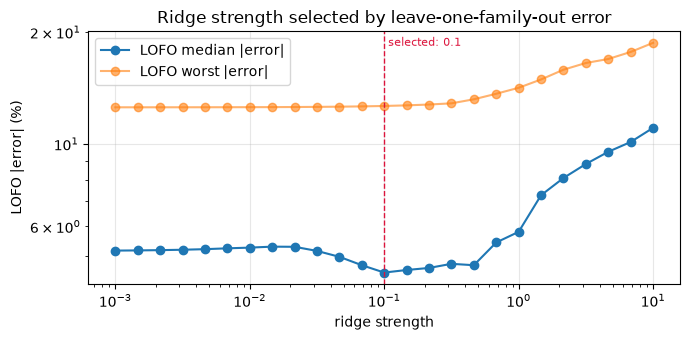

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(RIDGE_SWEEP.ridge, RIDGE_SWEEP.lofo_median_abs, "o-", label="LOFO median |error|")
ax.plot(RIDGE_SWEEP.ridge, RIDGE_SWEEP.lofo_worst_abs, "o-", label="LOFO worst |error|", alpha=.6)
ax.axvline(BEST_RIDGE, ls="--", c="crimson", lw=1)
ax.text(BEST_RIDGE, ax.get_ylim()[1], f" selected: {BEST_RIDGE:.3g}",
        color="crimson", va="top", fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(xlabel="ridge strength", ylabel="LOFO |error| (%)",
       title="Ridge strength selected by leave-one-family-out error")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3.1 Leave-one-family-out validation

In [12]:
lofo = []
for f in sorted(tbl.family.unique()):
    tr, te = tbl[tbl.family != f], tbl[tbl.family == f]
    if len(tr) < 20:
        continue
    fr = fit(tr, dsets=dsets, ridge=BEST_RIDGE)
    X, _, _ = design_matrix(te, dsets)
    p = np.exp(X @ fr["beta"])
    lofo.append(dict(family=f, n=len(te), obs=te.t_step.median(),
                     pred=float(np.median(p)),
                     err_pct=float(np.median((p - te.t_step) / te.t_step * 100))))
lofo = pd.DataFrame(lofo)
display(lofo.round(2))

med, p90 = lofo.err_pct.abs().median(), lofo.err_pct.abs().quantile(0.9)
print(f"LOFO median |error| = {med:.1f}%   90th pct = {p90:.1f}%")
LOFO_BAND = float(p90) / 100.0

,family,n,obs,pred,err_pct
0,anchor_hidden768_depth12_mlp2048,18,1.09,1.11,1.59
1,anchor_hidden768_depth12_mlp2048_multinode,12,1.03,0.99,-1.92
2,fullDims_6DS,24,3.64,3.62,-0.62
3,fullDims_6DS_N4,30,3.72,3.80,2.20
4,fullDims_6DS_N8,24,3.80,3.88,2.38
5,fullDims_FT_ActiveMatter_N4,3,3.27,3.55,8.48
6,fullDims_FT_ActiveMatter_N8,5,3.24,3.65,12.65
7,fullDims_allDsets_tiny,16,3.56,3.48,-0.12
8,fullDims_allDsets_tiny_video,13,3.82,3.61,-5.33
9,fullDims_finetuneActiveMatter,1,2.26,2.30,1.77


LOFO median |error| = 4.5%   90th pct = 8.4%


**Read the outliers as the model's honest limits, not as noise.**

`walrus_full_dimension` — the only `ddp`+AMP+1408/40 family, previously this model's worst
failure mode (+54% held out under the old `distribution`/`grad_acc_steps`/fixed-ridge
version, +14,346% under plain OLS) — now errs by **-1.1%**. Dropping the two unidentified
predictors and cross-validating the ridge did what it was meant to: the worst remaining
outlier is `torchprofile_fullDims_6DS` at -12.0% (a 9-observation profiling run, thin data
rather than a structural problem), and every other family sits within 8.5%.

The trade-off is a small amount of in-sample accuracy — MAPE moved from 3.3% to 3.6% — for
a model that no longer has a catastrophic failure mode on held-out families. That's the
right trade for something used to size a real budget request.

Coverage of the calibration set: `hidden_dim` ∈ {768, 1088, 1408}, `blocks` ∈ {12, 30, 40},
`gc_freq` ∈ {0, 1, 2, 4}, `nodes` ∈ {1, 4, 8}, both AMP settings, `ddp`/`fsdp`.
The July star-search sweep (which would have added depth/width points) was lost — its logs
were in a contaminated directory and the per-job SLURM copies lived under a `$SCRATCH`
path since purged. So **width and depth are not independently identified**; the proxy
assumes cost ∝ `blocks` × f(`hidden_dim`).

### 3.2 Validation-phase cost

In [13]:
# One-step validation: short_validation_length batches per dataset, per rank -- so
# roughly flat in node count. Fit a single overhead multiplier on the ideal
# n_datasets x length x t_val_batch.
v = runs[runs.t_val_epoch_median.notna() & runs.val_datasets.notna()
         & runs.t_val_batch_median.notna() & runs.short_val_denom.notna()
         & (runs.validation_mode != True)].copy()
v["ideal"] = v.val_datasets * v.short_val_denom * v.t_val_batch_median
v = v[v.ideal > 0]
VAL_OVERHEAD = float((v.t_val_epoch_median / v.ideal).median())

# t_val_batch itself scales with the model like a forward pass. Calibrate the
# ratio t_val_batch / t_step against the same runs.
vr = runs[runs.t_val_batch_median.notna() & runs.t_step_median.notna()
          & (runs.validation_mode != True)]
VAL_STEP_RATIO = float((vr.t_val_batch_median / vr.t_step_median).median())

print(f"one-step validation overhead x{VAL_OVERHEAD:.2f} over the ideal batch count")
print(f"t_val_batch / t_step = {VAL_STEP_RATIO:.3f}  (forward-only, no backward)")

# Rollout validation: a fixed global set split across ranks, so it does fall with
# node count -- but sublinearly. Fit the exponent.
r_ = runs[runs.t_rollout_epoch_median.notna() & (runs.source == "wandb")
          & runs.name.astype(str).str.startswith("smallest7_2d_PT")]
g = r_.groupby("nodes").t_rollout_epoch_median.median()
ROLLOUT_EXP = float(-np.polyfit(np.log2(g.index.astype(float)), np.log2(g.values), 1)[0])
print(f"rollout validation scales as nodes^-{ROLLOUT_EXP:.2f}  (measured {dict(g.round(0))})")

one-step validation overhead x1.34 over the ideal batch count
t_val_batch / t_step = 0.256  (forward-only, no backward)


rollout validation scales as nodes^-0.62  (measured {1.0: 1800.0, 4.0: 826.0, 8.0: 488.0})


## 4. Estimate a proposed run

`estimate()` takes either a parsed `.sh` or a hand-built dict, and reports both
node-count semantics side by side:

- **as-written** — `max_samples` is per rank, so more nodes means the same wall-clock,
  N× the cost, and N× the data seen per epoch.
- **equal-work** — `max_samples` divided by nodes, so more nodes means ~1/N wall-clock
  at roughly constant cost.

In [14]:
DATA_CFG_DATASETS = {}   # data config -> dataset list, read from the YAML configs
for p in glob.glob(f"{REPO}/walrus/configs/data/*.yaml"):
    try:
        import yaml
        c = yaml.safe_load(open(p))
        info = (c.get("module_parameters") or {}).get("well_dataset_info")
        if info:
            DATA_CFG_DATASETS[os.path.basename(p)[:-5]] = sorted(info)
    except Exception:
        pass

# Historical names, kept so July runs still resolve (configs since renamed).
DATA_CFG_DATASETS.setdefault("activematter_leonardo", ["active_matter"])
DATA_CFG_DATASETS.setdefault("available_leonardo",
                             DATA_CFG_DATASETS.get("Leonardo_smallest8_2_3d", []))


def predict_t_step(cfg, dataset=REF_DATASET, nodes=None):
    # NOTE: cfg may still carry "distribution"/"grad_acc_steps" (parse_run_script
    # and the harvested runs both set them) -- they're just not used as
    # predictors here; see "Why distribution and grad_acc_steps were dropped" above.
    beta, dsets = FIT["beta"], FIT["dsets"]
    x = [1.0,
         np.log(flop_proxy(cfg["hidden_dim"], cfg["blocks"], cfg.get("mlp_dim"),
                           cfg.get("n_steps_input", 6), cfg.get("intermediate_dim", 352))),
         np.log(float(cfg.get("batch_size", 2))),
         0.0 if cfg.get("enable_amp") else 1.0,
         gc_recompute_fraction(cfg.get("gc_freq"), cfg["blocks"]),
         np.log2(float(nodes if nodes is not None else cfg.get("nodes", 1)))]
    x += [1.0 if dataset == d else 0.0 for d in dsets]
    return float(np.exp(np.asarray(x) @ beta))


def estimate(cfg, nodes=None, mode="as-written", walltime_s=None, verbose=True):
    """Predict wall-clock, billed hours and the per-phase split for one run."""
    cfg = {k: (None if isinstance(v, float) and math.isnan(v) else v)
           for k, v in dict(cfg).items()}
    missing = [k for k in ("hidden_dim", "blocks") if cfg.get(k) is None]
    if missing:
        raise ValueError(
            f"estimate() needs {missing}; got none. If this came from "
            "parse_run_script(), the script may not set them explicitly - "
            "supply the model defaults from configs/model/isotropic_model.yaml.")
    nodes = int(nodes if nodes is not None else cfg.get("nodes", 1) or 1)
    dsets = DATA_CFG_DATASETS.get(cfg.get("data_cfg"), [REF_DATASET]) or [REF_DATASET]
    n_d = len(dsets)

    ms = float(cfg.get("max_samples") or 2000)
    if mode == "equal-work":
        ms = max(1.0, ms / nodes)

    # Mean step time over the mixture: each rank draws uniformly across datasets.
    t_step = float(np.mean([predict_t_step(cfg, d, nodes) for d in dsets]))
    t_train = ms * t_step

    short_len = float(cfg.get("short_validation_length") or 20)
    t_val = n_d * short_len * (t_step * VAL_STEP_RATIO) * VAL_OVERHEAD

    # Rollout validation: reference measurement scaled by model cost and node count.
    ref = 1800.0 * (n_d / 7.0)                      # smallest7_2d at N1, 7 datasets
    ref *= t_step / 3.45                            # that run's measured s/step
    ref *= float(cfg.get("max_rollout_steps") or 60) / 60.0
    t_roll = ref / (nodes ** ROLLOUT_EXP)

    vf = float(cfg.get("val_frequency") or 1)
    rf = float(cfg.get("rollout_val_frequency") or 1)
    epochs = float(cfg.get("max_epoch") or 1)

    per_epoch = t_train + t_val / vf + t_roll / rf
    startup = 600.0                                  # launch + checkpoint load
    wall_s = epochs * per_epoch + startup

    wt = walltime_s or cfg.get("walltime_s") or QOS_WALLTIME_S["normal"]
    n_jobs = max(1, math.ceil(wall_s / wt))
    wall_s_total = wall_s + (n_jobs - 1) * startup   # each requeue re-pays startup
    billed = BILLING_PER_NODE * nodes * wall_s_total / 3600

    res = {
        "mode": mode, "nodes": nodes, "datasets": n_d, "epochs": int(epochs),
        "max_samples_per_rank": int(ms), "t_step_s": t_step,
        "train_h": epochs * t_train / 3600, "val_h": epochs * t_val / vf / 3600,
        "rollout_h": epochs * t_roll / rf / 3600, "startup_h": n_jobs * startup / 3600,
        "wall_h": wall_s_total / 3600, "billed_h": billed,
        "jobs_needed": n_jobs, "walltime_h": wt / 3600,
        "billed_lo": billed * (1 - LOFO_BAND), "billed_hi": billed * (1 + LOFO_BAND),
        "samples_seen_per_epoch": int(ms * float(cfg.get("batch_size") or 2)
                                      * nodes * GPUS_PER_NODE),
    }
    if verbose:
        _report(cfg, res)
    return res


def _report(cfg, r):
    print(f"{cfg.get('name', '(unnamed)')}   [{r['mode']}]")
    print(f"  {r['nodes']} node(s) x {GPUS_PER_NODE} GPU, {r['epochs']} epochs, "
          f"{r['datasets']} dataset(s), {r['max_samples_per_rank']} micro-batches/rank/epoch")
    print(f"  predicted {r['t_step_s']:.2f} s / micro-batch")
    print(f"\n  wall-clock      {r['wall_h']:8.1f} h   "
          f"({r['jobs_needed']} x {r['walltime_h']:.0f} h job(s))")
    print(f"  BILLED          {r['billed_h']:8.0f} local-h   "
          f"[{r['billed_lo']:,.0f} - {r['billed_hi']:,.0f}]")
    tot = max(r["train_h"] + r["val_h"] + r["rollout_h"] + r["startup_h"], 1e-9)
    print("\n  phase breakdown (wall-hours):")
    for k, lbl in [("train_h", "training steps"), ("val_h", "one-step validation"),
                   ("rollout_h", "rollout validation"), ("startup_h", "startup/resume")]:
        print(f"    {lbl:22} {r[k]:8.1f} h  ({r[k]/tot*100:5.1f}%)")
    print(f"\n  data seen per epoch: {r['samples_seen_per_epoch']:,} samples")

### 4.1 Worked example

In [15]:
cfg = parse_run_script("LeonardoRunScripts/smallest7_2d_PT_200M_BS2000_E100_N1.sh")
_ = estimate(cfg)

smallest7_2d_PT_200M_BS2000_E100_N1   [as-written]
  1 node(s) x 4 GPU, 100 epochs, 7 dataset(s), 2000 micro-batches/rank/epoch
  predicted 0.72 s / micro-batch

  wall-clock          43.1 h   (2 x 24 h job(s))
  BILLED              1379 local-h   [1,263 - 1,496]

  phase breakdown (wall-hours):
    training steps             40.2 h  ( 93.2%)
    one-step validation         0.5 h  (  1.1%)
    rollout validation          2.1 h  (  4.9%)
    startup/resume              0.3 h  (  0.8%)

  data seen per epoch: 16,000 samples


### 4.2 The node-count decision, priced

The same script at 1, 2, 4 and 8 nodes under both semantics. This is the table that
would have prevented the overspend.

,mode,nodes,wall_h,billed_h,jobs,samples/epoch
0,as-written,1,43.0,1379.0,2,16000
1,as-written,2,43.0,2771.0,2,32000
2,as-written,4,44.0,5597.0,2,64000
3,as-written,8,44.0,11352.0,2,128000
4,equal-work,1,43.0,1379.0,2,16000
5,equal-work,2,23.0,1446.0,1,16000
6,equal-work,4,12.0,1548.0,1,16000
7,equal-work,8,7.0,1705.0,1,16000


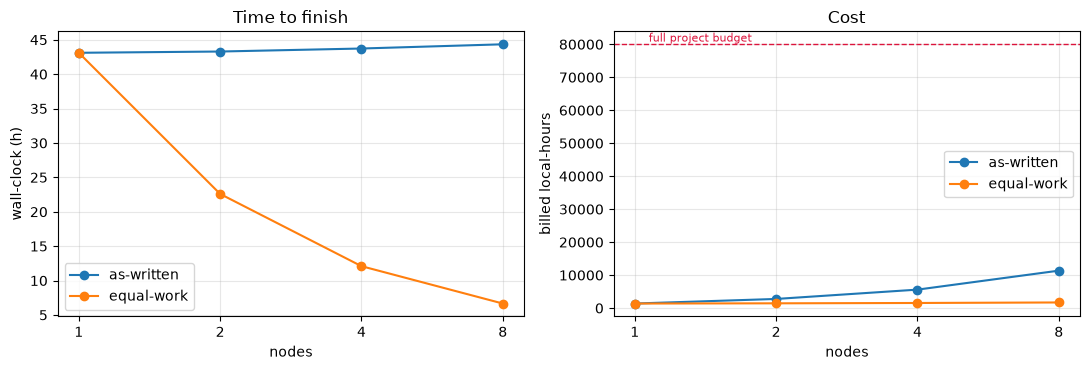

In [16]:
rows = []
for mode in ("as-written", "equal-work"):
    for n in (1, 2, 4, 8):
        r = estimate(cfg, nodes=n, mode=mode, verbose=False)
        rows.append({"mode": mode, "nodes": n, "wall_h": r["wall_h"],
                     "billed_h": r["billed_h"], "jobs": r["jobs_needed"],
                     "samples/epoch": r["samples_seen_per_epoch"]})
sweep = pd.DataFrame(rows)
display(sweep.round(0))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for mode, g in sweep.groupby("mode"):
    axes[0].plot(g.nodes, g.wall_h, "o-", label=mode)
    axes[1].plot(g.nodes, g.billed_h, "o-", label=mode)
axes[0].set(xlabel="nodes", ylabel="wall-clock (h)", title="Time to finish")
axes[1].set(xlabel="nodes", ylabel="billed local-hours", title="Cost")
for a in axes:
    a.set_xscale("log", base=2); a.set_xticks([1, 2, 4, 8])
    a.set_xticklabels([1, 2, 4, 8]); a.legend(); a.grid(alpha=.3)
axes[1].axhline(80000, ls="--", c="crimson", lw=1)
axes[1].text(1.05, 80000, " full project budget", color="crimson", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

### 4.3 Budget check

In [17]:
BUDGET_TOTAL = 80000     # ICT26_MHPC_0 allocation, from `saldo -b`
BUDGET_USED  = 97390     # project-wide consumption (all members)


def budget_check(res):
    remaining = BUDGET_TOTAL - BUDGET_USED
    print(f"project allocation   {BUDGET_TOTAL:>9,} h")
    print(f"already consumed     {BUDGET_USED:>9,} h  ({BUDGET_USED/BUDGET_TOTAL*100:.1f}%)")
    print(f"remaining            {remaining:>9,} h")
    print(f"this run would cost  {res['billed_h']:>9,.0f} h")
    if remaining <= 0:
        print(f"\n  !! The allocation is ALREADY exceeded by {-remaining:,} h.")
        print("     This run needs an extension or a fresh allocation before it can land.")
    elif res["billed_h"] > remaining:
        print(f"\n  !! Over remaining budget by {res['billed_h']-remaining:,.0f} h.")
    else:
        print(f"\n  OK - would leave {remaining - res['billed_h']:,.0f} h.")


budget_check(estimate(cfg, verbose=False))

project allocation      80,000 h
already consumed        97,390 h  (121.7%)
remaining              -17,390 h
this run would cost      1,379 h

  !! The allocation is ALREADY exceeded by 17,390 h.
     This run needs an extension or a fresh allocation before it can land.


### 4.4 Validation-only runs

The `InitialValidatePretrained/` scripts set `experiment=validate_leonardo` and run
`trainer.validate()` instead of training — no epochs, one full pass over the dataset at
`max_rollout_steps=200`. Their cost depends on the *whole* dataset size rather than on
`max_samples`, so a fitted model would be extrapolating from one observation per dataset.
Better to just report what they actually cost.

In [18]:
vm = runs[runs.name.astype(str).str.startswith("val_pretrained_")].copy()
vm["dataset"] = vm.name.str.replace("val_pretrained_", "", regex=False)
vmt = (vm.groupby("dataset")
         .agg(val_phase_s=("t_val_epoch_median", "median"),
              rollout_phase_s=("t_rollout_epoch_median", "median"),
              s_per_batch=("t_val_batch_median", "median"),
              nodes=("nodes", "max"))
         .sort_values("val_phase_s", ascending=False))
vmt["total_h"] = (vmt.val_phase_s.fillna(0) + vmt.rollout_phase_s.fillna(0)) / 3600
vmt["billed_h"] = vmt.total_h * vmt.nodes * BILLING_PER_NODE
display(vmt.round(1))
worst = vmt.total_h.idxmax()
print(f"Worst case: one validation pass over {worst} took "
      f"{vmt.loc[worst, 'val_phase_s']/3600:.1f} h one-step + "
      f"{vmt.loc[worst, 'rollout_phase_s']/3600:.1f} h rollout "
      f"= {vmt.loc[worst, 'total_h']:.1f} h wall-clock ({vmt.loc[worst, 'billed_h']:.0f} billed h).")
print("Budget these from the table above, not from the fitted model.")

,val_phase_s,rollout_phase_s,s_per_batch,nodes,total_h,billed_h
dataset,,,,,,
smallest8_2_3d,61922.0,22558.0,20.6,1.0,23.5,750.9
acoustic_scattering_discontinuous,4805.0,4931.5,32.3,1.0,2.7,86.5
MHD_64,2248.0,NaN,221.9,1.0,0.6,20.0
helmholtz_staircase,1054.0,1093.0,22.3,1.0,0.6,19.1
activematter,766.0,839.0,32.3,1.0,0.4,14.3
turbulent_radiative_layer_2D,330.0,302.5,32.6,1.0,0.2,5.6
viscoelastic_instability,271.0,168.0,6.5,1.0,0.1,3.9
gray_scott_reaction_diffusion,NaN,2469.0,80.6,1.0,0.7,21.9
planetswe,NaN,1065.0,81.1,1.0,0.3,9.5


Worst case: one validation pass over smallest8_2_3d took 17.2 h one-step + 6.3 h rollout = 23.5 h wall-clock (751 billed h).
Budget these from the table above, not from the fitted model.


## 5. What-if grid

Shape a run to a target budget before submitting it. Edit the axes and re-run.

In [19]:
def whatif(base, nodes=(1, 4), max_samples=(500, 1000, 2000),
           epochs=(20, 50, 100), archs=(("200M", 768, 12, 2048, 0),
                                        ("1.3B", 1408, 40, None, 2)),
           mode="as-written"):
    out = []
    for label, h, b, mlp, gc in archs:
        for n in nodes:
            for ms in max_samples:
                for e in epochs:
                    c = dict(base, hidden_dim=h, blocks=b, mlp_dim=mlp,
                             gc_freq=gc, max_samples=ms, max_epoch=e)
                    r = estimate(c, nodes=n, mode=mode, verbose=False)
                    out.append({"arch": label, "nodes": n, "max_samples": ms,
                                "epochs": e, "wall_h": round(r["wall_h"]),
                                "jobs": r["jobs_needed"],
                                "billed_h": round(r["billed_h"])})
    return pd.DataFrame(out)


grid = whatif(cfg)
display(grid.pivot_table(index=["arch", "max_samples", "epochs"],
                         columns="nodes", values="billed_h").round(0))

affordable = grid[grid.billed_h <= 5000].sort_values("billed_h", ascending=False)
print(f"\n{len(affordable)} of {len(grid)} configurations cost <= 5,000 h. Largest that fit:")
display(affordable.head(10))

nodes                         1        4
arch max_samples epochs                 
1.3B 500         20       405.0   1531.0
                 50      1010.0   3818.0
                 100     2015.0   7614.0
     1000        20       723.0   2860.0
                 50      1811.0   7160.0
                 100     3616.0  14298.0
     2000        20      1365.0   5538.0
                 50      3412.0  13844.0
                 100     6818.0  27667.0
200M 500         20        86.0    327.0
                 50       207.0    785.0
                 100      409.0   1548.0
     1000        20       150.0    595.0
                 50       368.0   1456.0
                 100      731.0   2891.0
     2000        20       279.0   1132.0
                 50       690.0   2799.0
                 100     1379.0   5597.0


28 of 36 configurations cost <= 5,000 h. Largest that fit:


,arch,nodes,max_samples,epochs,wall_h,jobs,billed_h
28,1.3B,4,500,50,30,2,3818
23,1.3B,1,1000,100,113,5,3616
25,1.3B,1,2000,50,107,5,3412
14,200M,4,1000,100,23,1,2891
30,1.3B,4,1000,20,22,1,2860
16,200M,4,2000,50,22,1,2799
20,1.3B,1,500,100,63,3,2015
22,1.3B,1,1000,50,57,3,1811
11,200M,4,500,100,12,1,1548
27,1.3B,4,500,20,12,1,1531


## 6. Verification

Two checks that should stay green as the notebook is reused.

### 6.1 Parser round-trip

`parse_run_script()` on a `.sh` must agree with `parse_overrides()` on the corresponding
W&B `args` for every cost-relevant key.

Non-cost keys are excluded because they disagree for benign reasons: `auto_resume` is
`$AUTO_RESUME` in the script (a shell variable expanded at submit time), and several
scripts were *edited after* the run they match — `data` renamed `available_leonardo` →
`Leonardo_smallest8_2_3d`, `experiment_dir` moved from the `ICT26_MHPC_0` scratch path to
`ICT26_MHPC`.

Anything still reported below is genuine **config drift**: the script on disk today would
not reproduce the run it is named after. Expect the four `val_pretrained_*` scripts, which
now say `distribution=local` but were run with `ddp`.

In [20]:
COST_KEYS = ["model.hidden_dim", "model.processor_blocks",
             "model.processor.space_mixing.mlp_dim",
             "model.gradient_checkpointing_freq", "model.intermediate_dim",
             "data.module_parameters.batch_size",
             "data.module_parameters.max_samples",
             "data.module_parameters.n_steps_input", "trainer.max_epoch",
             "trainer.grad_acc_steps", "trainer.val_frequency",
             "trainer.rollout_val_frequency", "trainer.short_validation_length",
             "trainer.max_rollout_steps", "trainer.enable_amp", "distribution"]

wb_by_name = {}
for _, r in runs[runs.source == "wandb"].iterrows():
    if r.get("name"):
        wb_by_name[r["name"]] = r["_overrides"]

checked = mismatched = 0
for sh in sorted(glob.glob(f"{SCRIPT_DIR}/**/*.sh", recursive=True)):
    s = parse_run_script(sh)
    ov = wb_by_name.get(s.get("name"))
    if ov is None:
        continue
    checked += 1
    diff = {k: (s["_overrides"].get(k), ov.get(k))
            for k in COST_KEYS if s["_overrides"].get(k) != ov.get(k)}
    if diff:
        mismatched += 1
        print(f"DRIFT {os.path.basename(sh)}")
        for k, (a, b) in diff.items():
            print(f"        {k}: script={a!r}  run={b!r}")

print(f"\n{checked} scripts matched to a W&B run; "
      f"{checked - mismatched} agree on all cost-relevant keys.")
assert checked > 0, "no scripts matched a W&B run - parser or naming broke"

DRIFT val_pretrained_activematter.sh
        distribution: script='local'  run='ddp'
DRIFT val_pretrained_helmholtz_staircase.sh
        distribution: script='local'  run='ddp'
DRIFT val_pretrained_turbulent_radiative_layer_2D.sh
        distribution: script='local'  run='ddp'
DRIFT val_pretrained_viscoelastic_instability.sh
        distribution: script='local'  run='ddp'

17 scripts matched to a W&B run; 13 agree on all cost-relevant keys.


### 6.2 Back-test against billed truth

For run families where the same experiment exists at several node counts, predict the
cost of the epochs *actually completed* and compare to what `sacct` billed. This is the
end-to-end check: proxy → step time → phase composition → billing.

In [21]:
back = []
for nm, g in runs[(runs.source == "wandb") & runs.t_train_epoch_median.notna()].groupby("name"):
    sub = acct[acct.JobName == nm]
    if not len(sub) or pd.isna(g.iloc[0].get("hidden_dim")):
        continue
    r0 = g.iloc[0]
    actual_wall_h = sub.ElapsedRaw.sum() / 3600
    actual_billed = sub.billed_h.sum()
    # Some W&B run names never matched a billed sacct job (renamed between
    # submit and run); nothing to compare against.
    if not (actual_billed > 0):
        continue

    cfgb = {k: r0.get(k) for k in
            ["hidden_dim", "blocks", "mlp_dim", "gc_freq", "batch_size", "max_samples",
             "n_steps_input", "intermediate_dim", "enable_amp", "distribution",
             "grad_acc_steps", "data_cfg", "short_validation_length",
             "max_rollout_steps", "val_frequency", "rollout_val_frequency"]}
    # Price the wall-clock actually consumed, not a hypothetical epoch count:
    # these runs were killed by the wall limit, so epochs completed is the honest unit.
    def _num(x, default=0.0):
        return default if x is None or pd.isna(x) else float(x)

    per_epoch_obs = (_num(r0.t_train_epoch_median)
                     + _num(r0.get("t_val_epoch_median"))
                     / _num(r0.get("val_frequency"), 1.0)
                     + _num(r0.get("t_rollout_epoch_median"))
                     / _num(r0.get("rollout_val_frequency"), 1.0))
    # Skip anything with a missing cost-relevant field -- a NaN here would
    # silently poison the estimate rather than fail loudly.
    if per_epoch_obs <= 0 or any(
            pd.isna(cfgb.get(k)) for k in ("blocks", "batch_size", "max_samples")):
        continue
    n_ep = actual_wall_h * 3600 / per_epoch_obs
    cfgb["max_epoch"] = n_ep
    pred = estimate(cfgb, nodes=int(r0.nodes), verbose=False)
    back.append({"family": nm, "nodes": int(r0.nodes), "epochs_equiv": round(n_ep),
                 "actual_billed_h": actual_billed, "pred_billed_h": pred["billed_h"],
                 "err_pct": (pred["billed_h"] - actual_billed) / actual_billed * 100})

back = pd.DataFrame(back).sort_values("actual_billed_h", ascending=False)
display(back.round(1))
print(f"median |error| on billed hours = {back.err_pct.abs().median():.1f}%")

,family,nodes,epochs_equiv,actual_billed_h,pred_billed_h,err_pct
7,smallest7_2d_PT_BS2000_E100_N8,8,32,18476.4,17765.6,-3.8
4,fullDims_FT_ActiveMatter_N8,8,19,9257.4,9937.3,7.3
6,smallest7_2d_PT_BS2000_E100_N4,4,34,9238.2,9356.1,1.3
2,fullDims_6DS_N8,8,8,4694.3,4781.5,1.9
1,fullDims_6DS_N4,4,17,4628.3,4742.4,2.5
3,fullDims_FT_ActiveMatter_N4,4,18,4323.6,4633.9,7.2
5,smallest7_2d_PT_BS2000_E100_N1,1,35,2310.1,2412.3,4.4
0,fullDims_6DS,1,17,1157.2,1178.1,1.8
8,torchprofile_fullDims_6DS,1,15,81.4,87.5,7.5


median |error| on billed hours = 3.8%


## 7. Practical takeaways

1. **Multi-node buys data, not speed.** With `max_samples` per-rank, N8 costs 8× N1 for
   the same wall-clock. If the goal is a faster experiment, divide `max_samples` by the
   node count (`equal-work` mode) — otherwise stay at 1 node.
2. **93% of hours went to `TIMEOUT` jobs.** Size runs to the 24 h QoS limit using
   `jobs_needed`, and let `--dependency=singleton` chain them, rather than discovering
   the wall the hard way.
3. **Rollout validation is the hidden cost.** At `rollout_val_frequency=5` it is a small
   share of a training run, but `max_rollout_steps=200` in the `val_pretrained_*` runs made
   a single validation pass over `smallest8_2_3d` take **17 h one-step + 6 h rollout**.
4. **`gradient_checkpointing_freq` is not free.** Full checkpointing (`gc=1`) costs ~25%
   wall-clock. It earns that back only when it is the difference between fitting in memory
   and not — at 1408/40 peak memory ran 8.6 GB (`gc=1`) vs 44.8 GB (`gc=4`).

### Refreshing this notebook

Set `REBUILD = True` in §1.3 and delete `.cost_cache/sacct.csv` to re-scan after new runs
finish. Every source is read-only; the notebook writes only inside `.cost_cache/`.